# 03 – Analyse : décès accidentels liés aux drogues (Connecticut, 2012-2022)

Ce notebook part du fichier nettoyé `data/processed/deces_nettoyes.csv` produit par `02_nettoyage.ipynb`.
Il répond aux questions métier par des agrégations et des visualisations.

**Questions étudiées :**
1. Parmi les 5 substances les plus souvent détectées, quelle part des décès implique chacune, et comment cette part a-t-elle évolué de 2012 à 2022 ?
2. Quelles associations de substances reviennent le plus souvent parmi les décès ?
3. Quel est le profil (âge, sexe) des personnes décédées, et a-t-il changé entre 2012 et 2022 ?
4. Quels comtés comptent le plus de décès, en nombre et rapporté à leur population ?
5. Les décès surviennent-ils majoritairement au domicile ou à l'hôpital ?

Rappel : on compte des **détections** de substances, pas des causes. Un décès peut impliquer plusieurs substances.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

deces = pd.read_csv("../data/processed/deces_nettoyes.csv", parse_dates=["Date"])
print(deces.shape)

(10653, 46)


In [2]:
colonnes_substances = deces.loc[:, "Heroin":"Any Opioid"].columns
print(deces["Date"].dtype)
print(deces[colonnes_substances].dtypes.value_counts())

datetime64[us]
bool    21
Name: count, dtype: int64


## Q1 – Quelles substances sont le plus souvent détectées, et comment leur part a-t-elle évolué ?

Pour classer les substances, on exclut 4 colonnes qui ne désignent pas une substance précise mais un **regroupement** ou une **mention administrative** :
`Any Opioid` (tout opioïde confondu), `Heroin/Morph/Codeine` et `Opiate NOS` (catégories regroupées ou non précisées), `Heroin death certificate (DC)` (mention sur le certificat de décès, qui doublonne `Heroin`).
Les garder ferait monter artificiellement des catégories qui recoupent les autres. On classe donc les 17 substances restantes.

In [3]:
colonnes_exclues = ["Any Opioid", "Heroin/Morph/Codeine", "Opiate NOS", "Heroin death certificate (DC)"]
substances_individuelles = deces[colonnes_substances].drop(columns=colonnes_exclues)
detections_par_substance = substances_individuelles.sum()
detections_par_substance = detections_par_substance.sort_values(ascending=False)
print(detections_par_substance)

Fentanyl                 6925
Cocaine                  3855
Heroin                   3472
Ethanol                  2877
Benzodiazepine           2499
Oxycodone                 949
Methadone                 938
Fentanyl Analogue         804
Xylazine                  792
Amphet                    359
Gabapentin                348
Tramad                    284
Hydrocodone               163
Oxymorphone               157
Meth/Amphetamine          127
Hydromorphone              67
Morphine (Not Heroin)      52
dtype: int64


In [4]:
top5_substances = list(detections_par_substance.index[:5])
part_deces_top5 = deces[top5_substances].mean()
part_deces_top5 = part_deces_top5.sort_values(ascending=False)
print(top5_substances)
print(part_deces_top5)

['Fentanyl', 'Cocaine', 'Heroin', 'Ethanol', 'Benzodiazepine']
Fentanyl          0.650052
Cocaine           0.361870
Heroin            0.325918
Ethanol           0.270065
Benzodiazepine    0.234582
dtype: float64


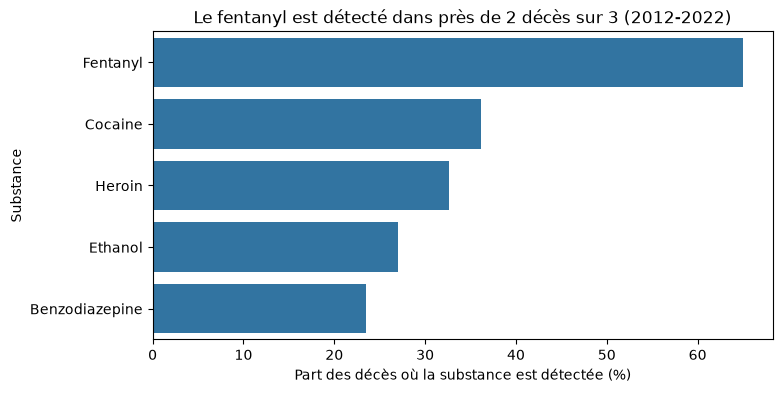

In [5]:
pourcentage_top5 = part_deces_top5 * 100

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=pourcentage_top5.values, y=pourcentage_top5.index, ax=ax)
ax.set_title("Le fentanyl est détecté dans près de 2 décès sur 3 (2012-2022)")
ax.set_xlabel("Part des décès où la substance est détectée (%)")
ax.set_ylabel("Substance")
fig.savefig("../figures/01_top5_substances.png")
plt.show()

**Conclusion :** sur l'ensemble de la période 2012-2022, le fentanyl est détecté dans 65,0 % des décès, soit près de 2 sur 3. C'est près de deux fois plus que la cocaïne (36,2 %) et l'héroïne (32,6 %), qui suivent à un niveau proche. L'alcool (27,0 %) et les benzodiazépines (23,5 %) complètent le top 5. Ces parts portent sur toute la période : la suite vérifie si cette domination du fentanyl a toujours existé ou si elle est récente.

In [6]:
deces["Annee"] = deces["Date"].dt.year
part_par_annee = deces.groupby("Annee")[top5_substances].mean() * 100
print(part_par_annee.round(1))

       Fentanyl  Cocaine  Heroin  Ethanol  Benzodiazepine
Annee                                                    
2012        4.0     29.7    49.2     17.2            13.8
2013        7.6     30.0    52.4     16.9            15.9
2014       13.4     22.8    58.2     22.6            28.1
2015       25.9     24.3    57.2     24.1            30.3
2016       52.6     30.0    53.9     27.8            26.4
2017       65.1     33.4    45.7     27.9            31.8
2018       74.7     33.9    38.4     25.1            26.3
2019       81.6     38.6    32.2     28.5            24.2
2020       84.4     38.5    19.1     29.4            22.3
2021       85.4     43.0    10.9     31.3            19.5
2022       86.3     47.1     8.6     28.1            18.0


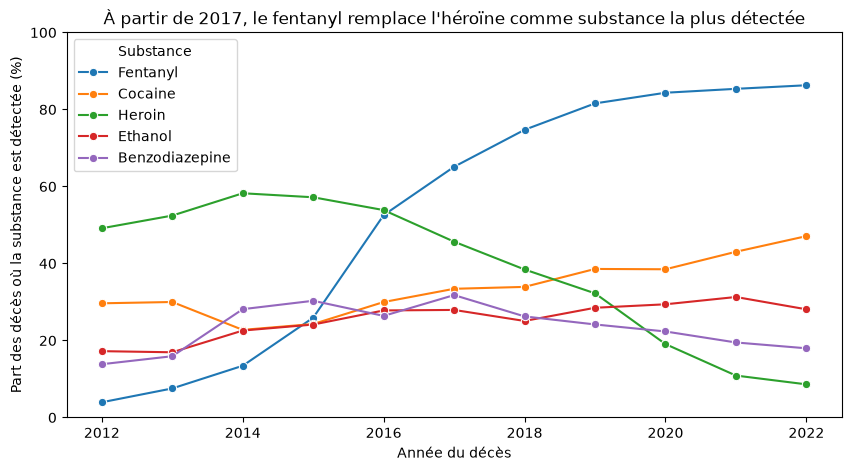

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=part_par_annee, dashes=False, marker="o", ax=ax)
ax.set_title("À partir de 2017, le fentanyl remplace l'héroïne comme substance la plus détectée")
ax.set_xlabel("Année du décès")
ax.set_ylabel("Part des décès où la substance est détectée (%)")
ax.set_ylim(0, 100)
ax.legend(title="Substance")
fig.savefig("../figures/02_evolution_top5.png")
plt.show()

**Conclusion :** le profil des substances détectées s'est profondément transformé en 11 ans.
- Le **fentanyl** passe de 4,0 % des décès en 2012 à 86,3 % en 2022.
- L'**héroïne** atteint son maximum en 2014 (58,2 %), puis recule nettement à partir de 2016-2017 jusqu'à 8,6 % en 2022.
- Les deux courbes se croisent en **2017** : le fentanyl est alors détecté dans 65,1 % des décès, contre 45,7 % pour l'héroïne (en 2016, les deux étaient encore au coude-à-coude : 52,6 % contre 53,9 %).
- La **cocaïne** progresse aussi, de 29,7 % à 47,1 %, après un creux en 2014 (22,8 %).

Ces données montrent un **remplacement** de l'héroïne par le fentanyl parmi les substances détectées. Elles ne disent pas pourquoi : le jeu de données ne contient que des décès, il ne permet pas de mesurer la consommation.